# 02 | U-Net Baseline Training and Hyperparameter Optimization

**Evaluating Underwater Image Enhancement for CNN-Based Robotic Segmentation**  

## Research objective

I develop a reproducible U-Net baseline for eight-class semantic segmentation of underwater scenes. The model is trained exclusively on RAW SUIM images. I compare optimization configurations using the validation partition, then train a new model with the selected configuration and retain its strongest validation checkpoint. This establishes a fixed segmentation model for the later RAW, CLAHE, and FUnIE-GAN comparison.

The official test partition is reserved for the final enhancement study and is not used to select hyperparameters or interpret the baseline during development.

**Experimental sequence:** data verification → architecture inspection → four controlled 20-epoch tuning experiments → validation-based selection → fresh 60-epoch final training → quantitative and qualitative validation analysis.

## 1. Experimental environment and reproducibility

I use a GPU-enabled Colab environment and keep model artifacts in Google Drive. The project is restored from the archived source when needed, while the reviewed dataset manifest and exclusions remain fixed across experiments. Random seeds, package versions, and a manifest checksum support reproducibility.

In [ ]:
import os
import sys
import json
import time
import random
import hashlib
import shutil
import zipfile
import subprocess
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from PIL import Image
from IPython.display import display
from google.colab import drive

drive.mount('/content/drive')
DRIVE_ROOT = Path('/content/drive/MyDrive/Underwater_Research')
PROJECT = Path('/content/suim_project')
SOURCE = PROJECT / 'src'
MANIFEST = PROJECT / 'results/tables/notebook_01/manifest.csv'
RUN_ROOT = DRIVE_ROOT / 'checkpoints/notebook_02_public_research_v1'
RUN_ROOT.mkdir(parents=True, exist_ok=True)

archive_path = DRIVE_ROOT / 'underwater-robotic-segmentation.zip'
assert archive_path.is_file(), 'Project archive is unavailable in Google Drive.'
assert (DRIVE_ROOT / 'manifest.csv').is_file(), 'Finalized manifest is unavailable in Google Drive.'
assert (DRIVE_ROOT / 'exclusions.csv').is_file(), 'Reviewed exclusions are unavailable in Google Drive.'

if not (SOURCE / 'train.py').is_file() or not (PROJECT / 'data/SUIM').is_dir():
    with zipfile.ZipFile(archive_path) as archive:
        names = [m.filename for m in archive.infolist() if m.filename.endswith('src/train.py')]
        assert len(names) == 1, 'Unable to identify the project root in the archive.'
        prefix = names[0][:-len('src/train.py')]
        for member in archive.infolist():
            if member.is_dir() or not member.filename.startswith(prefix):
                continue
            relative = Path(member.filename[len(prefix):])
            if not relative.parts or '..' in relative.parts or relative.is_absolute():
                continue
            if relative.parts[0] not in {'src', 'data'}:
                continue
            destination = PROJECT / relative
            destination.parent.mkdir(parents=True, exist_ok=True)
            with archive.open(member) as src, destination.open('wb') as dst:
                shutil.copyfileobj(src, dst)

SOURCE.mkdir(parents=True, exist_ok=True)
for filename in ['common.py', 'dataset.py', 'unet.py', 'train.py', 'build_manifest.py']:
    source_file = DRIVE_ROOT / 'source_review' / filename
    assert source_file.is_file(), f'Missing source module: {filename}'
    shutil.copy2(source_file, SOURCE / filename)

MANIFEST.parent.mkdir(parents=True, exist_ok=True)
for filename in ['manifest.csv', 'exclusions.csv']:
    shutil.copy2(DRIVE_ROOT / filename, MANIFEST.parent / filename)

os.chdir(PROJECT)
if str(SOURCE) not in sys.path:
    sys.path.insert(0, str(SOURCE))
from unet import SmallUNet
from dataset import SuimDataset, DEFAULT_MANIFEST
from common import CLASS_NAMES, NUM_CLASSES, miou, iou_per_class
from train import evaluate, set_seed

SEED = 42
set_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
assert DEVICE.type == 'cuda', 'A GPU runtime is required for the training experiments.'
print('GPU:', torch.cuda.get_device_name(0))
print('PyTorch:', torch.__version__)
sns.set_theme(style='whitegrid', context='notebook', palette='deep')
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 180, 'axes.titlesize': 12})
print('Output directory:', RUN_ROOT)

Mounted at /content/drive
GPU: Tesla T4
PyTorch: 2.14.1+cu130
Output directory: /content/drive/MyDrive/Underwater_Research/checkpoints/notebook_02_public_research_v1


## 2. Dataset integrity and partition verification

The finalized SUIM dataset contains 1,204 training images, 214 validation images, and 110 reserved test images. I verify the split sizes, unique image identifiers, and 107 reviewed exclusions before fitting the model. Hyperparameter selection and the analysis in this notebook use only training and validation images.

In [ ]:
df = pd.read_csv(MANIFEST)
assert set(df.columns) >= {'split','stem'}
counts = df['split'].value_counts().to_dict()
assert counts == {'train': 1204, 'val': 214, 'test': 110}, f'Unexpected split: {counts}'
assert df['stem'].is_unique, 'Duplicate stems found across splits'
assert str(DEFAULT_MANIFEST) == 'results/tables/notebook_01/manifest.csv'
manifest_hash = hashlib.sha256(MANIFEST.read_bytes()).hexdigest()
print('Locked manifest SHA256:', manifest_hash)
display(pd.DataFrame({'split':list(counts),'images':list(counts.values())}))
print('Manifest integrity verified.')

exclusions = pd.read_csv(MANIFEST.parent / 'exclusions.csv')
assert len(exclusions) == 107, f'Unexpected exclusions: {len(exclusions)}'
assert df.groupby('stem')['split'].nunique().max() == 1
print('Reviewed exclusions:', len(exclusions))

Locked manifest SHA256: 30713993fb9fbd669bee764758ccd3c2fd83cf9af953295c0940e5ccdca97b69


,split,images
0,train,1204
1,val,214
2,test,110


Manifest integrity verified.
Reviewed exclusions: 107


## 3. Input representation and U-Net architecture

I use the same 256 × 256 image resolution and eight-class mask encoding established during data preparation. The U-Net combines spatial feature extraction in its encoder with upsampling and skip connections in its decoder. This structure retains both broader scene context and local detail needed for pixel-level predictions. I inspect one validation sample and verify the network output dimensions before training.

Input: (3, 256, 256) mask: (256, 256) output: (1, 8, 256, 256)
Parameters: 1,942,696


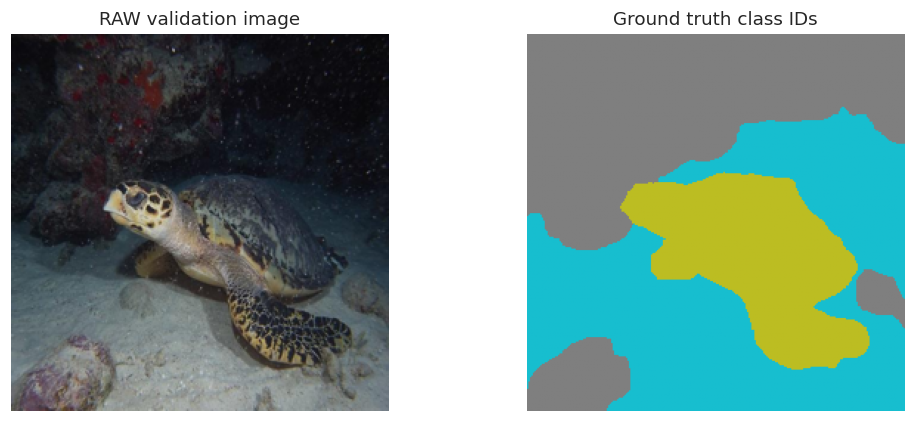

In [ ]:
train_ds = SuimDataset('train', manifest=MANIFEST, augment=True)
val_ds = SuimDataset('val', manifest=MANIFEST, augment=False)
x, y = val_ds[0]
model_check = SmallUNet(num_classes=NUM_CLASSES).to(DEVICE)
model_check.eval()
with torch.no_grad():
    logits = model_check(x.unsqueeze(0).to(DEVICE))
assert x.shape == (3,256,256) and y.shape == (256,256)
assert logits.shape == (1,8,256,256)
assert 0 <= int(y.min()) <= int(y.max()) <= 7
print('Input:',tuple(x.shape),'mask:',tuple(y.shape),'output:',tuple(logits.shape))
print('Parameters:',f'{sum(p.numel() for p in model_check.parameters()):,}')
fig,ax=plt.subplots(1,2,figsize=(10,4))
ax[0].imshow((x.permute(1,2,0).numpy()+1)/2);ax[0].set_title('RAW validation image')
ax[1].imshow(y.numpy(),vmin=0,vmax=7,cmap='tab10');ax[1].set_title('Ground truth class IDs')
for a in ax:a.axis('off')
plt.tight_layout();plt.show()
del model_check, logits
if torch.cuda.is_available():torch.cuda.empty_cache()

## 4. Controlled hyperparameter design

I compare two learning rates (0.001 and 0.0003) and two objectives (cross-entropy and cross-entropy plus Dice loss). Each configuration receives up to 20 epochs under the same model architecture, optimizer family, training partition, and validation metric. I use validation mean intersection-over-union (mIoU) to select the configuration because it directly measures segmentation overlap across classes.

**Monitoring:** every completed epoch is printed live with training loss, validation loss, validation mIoU, validation pixel accuracy, learning rate, and the best score so far. The same values are stored in CSV histories.

In [ ]:
assert 'pixel_accuracy' in Path(SOURCE / 'train.py').read_text(), 'Updated live-metrics train.py is required.'
RUN_TUNING = True
TUNING_EPOCHS = 20
TUNING_PATIENCE = 8
BATCH_SIZE = 8
WORKERS = 0
TRIALS = [
    {'name':'lr1e3_ce',      'lr':1e-3, 'loss':'ce'},
    {'name':'lr3e4_ce',      'lr':3e-4, 'loss':'ce'},
    {'name':'lr1e3_ce_dice', 'lr':1e-3, 'loss':'ce_dice'},
    {'name':'lr3e4_ce_dice', 'lr':3e-4, 'loss':'ce_dice'},
]

def train_command(out, lr, loss, epochs, patience, resume=False):
    cmd=[sys.executable,'-u','src/train.py','--manifest',str(MANIFEST),
         '--epochs',str(epochs),'--patience',str(patience),
         '--batch-size',str(BATCH_SIZE),'--lr',str(lr),
         '--weight-decay','0.0001','--loss',loss,
         '--seed',str(SEED),'--workers',str(WORKERS),
         '--out',str(out)]
    if resume:cmd.append('--resume')
    return cmd

def run_training(out, lr, loss, epochs, patience):
    out = Path(out)
    last = out / 'last.pth'
    summary = out / 'best_validation.json'
    history_path = out / 'history.csv'
    if summary.exists() and history_path.exists():
        history = pd.read_csv(history_path)
        if len(history) >= epochs or (len(history) >= patience and
            int(history['epoch'].iloc[-1]) - int(history.loc[history['val_miou'].idxmax(), 'epoch']) >= patience):
            print('Completed:', out.name)
            return
    print(('Resuming' if last.exists() else 'Starting'), out.name, flush=True)
    process = subprocess.Popen(train_command(out, lr, loss, epochs, patience, resume=last.exists()),
                               cwd=PROJECT, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                               text=True, bufsize=1)
    for line in process.stdout:
        print(line, end='', flush=True)
    code = process.wait()
    if code != 0:
        raise RuntimeError(f'Training failed for {out.name} (exit code {code}). See output above.')

print('Trials:',len(TRIALS),'| max epochs each:',TUNING_EPOCHS)
print('Live epoch metrics: training loss, validation loss, mIoU, pixel accuracy, learning rate.')

Trials: 4 | max epochs each: 20
Live epoch metrics: training loss, validation loss, mIoU, pixel accuracy, learning rate.


## 5. Hyperparameter optimization

I fit each configuration on RAW images and monitor the validation results after every epoch. Early stopping limits unnecessary computation when mIoU stops improving. The strongest checkpoint and the latest resumable checkpoint are retained separately for each experiment.

In [ ]:
if RUN_TUNING:
    for t in TRIALS:
        run_training(RUN_ROOT/'tuning'/t['name'],t['lr'],t['loss'],TUNING_EPOCHS,TUNING_PATIENCE)
else:
    print('Tuning skipped by user setting. Existing results will be read below.')

Starting lr1e3_ce
Device: cuda; train=1204 val=214; parameters=1,942,696
Epoch 01/20 | train_loss=1.4917 val_loss=1.3157 | val_mIoU=0.1428 | pixel_acc=57.42% | best_mIoU=0.1428 (epoch 1) | lr=0.001 | 32s
Epoch 02/20 | train_loss=1.2471 val_loss=1.2415 | val_mIoU=0.1563 | pixel_acc=58.69% | best_mIoU=0.1563 (epoch 2) | lr=0.001 | 30s
Epoch 03/20 | train_loss=1.1854 val_loss=1.2113 | val_mIoU=0.1682 | pixel_acc=59.33% | best_mIoU=0.1682 (epoch 3) | lr=0.001 | 30s
Epoch 04/20 | train_loss=1.1739 val_loss=1.1591 | val_mIoU=0.1790 | pixel_acc=60.87% | best_mIoU=0.1790 (epoch 4) | lr=0.001 | 30s
Epoch 05/20 | train_loss=1.1579 val_loss=1.1746 | val_mIoU=0.1824 | pixel_acc=59.32% | best_mIoU=0.1824 (epoch 5) | lr=0.001 | 31s
Epoch 06/20 | train_loss=1.1367 val_loss=1.1266 | val_mIoU=0.1768 | pixel_acc=60.99% | best_mIoU=0.1824 (epoch 5) | lr=0.001 | 32s
Epoch 07/20 | train_loss=1.1200 val_loss=1.1341 | val_mIoU=0.1768 | pixel_acc=61.00% | best_mIoU=0.1824 (epoch 5) | lr=0.001 | 31s
Epoch 08/2

## 6. Hyperparameter comparison and model selection

I rank the four experiments by their best validation mIoU and examine the learning trajectories rather than relying on final-epoch results alone. Pixel accuracy provides a complementary summary, but it can be dominated by large classes; mIoU remains the selection criterion.

,trial,lr,loss,best_epoch,best_val_miou,best_val_loss,epochs_run
0,lr3e4_ce_dice,3e-04,ce_dice,20,0.2859,1.5997,20
1,lr1e3_ce_dice,1e-03,ce_dice,18,0.2656,1.6801,20
2,lr3e4_ce,3e-04,ce,18,0.2552,0.9794,20
3,lr1e3_ce,1e-03,ce,18,0.2368,1.0502,20


Selected: {'selected_trial': 'lr3e4_ce_dice', 'lr': 0.0003, 'loss': 'ce_dice', 'selection_metric': 'best validation mIoU', 'manifest_sha256': '30713993fb9fbd669bee764758ccd3c2fd83cf9af953295c0940e5ccdca97b69', 'selected_at': '2026-11-20T23:42:50'}


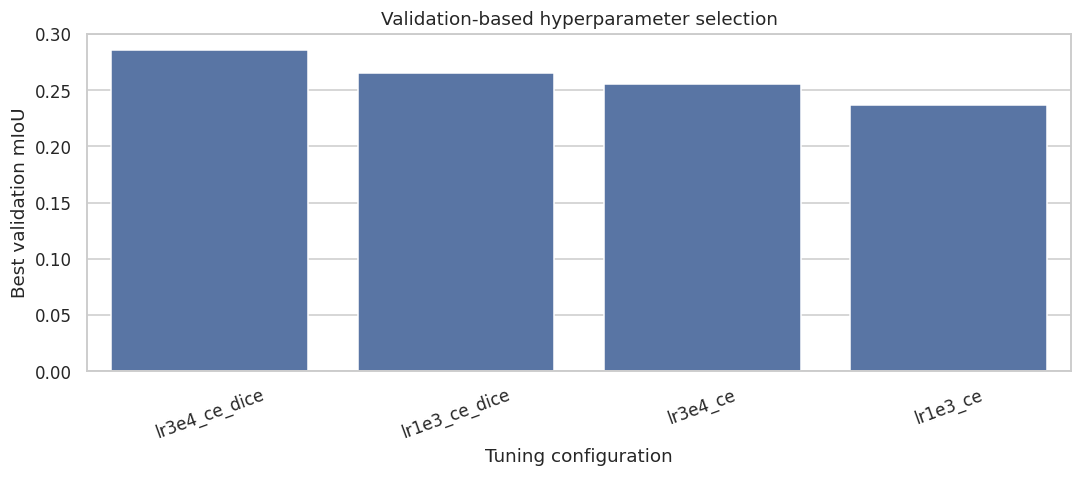

In [ ]:
trial_rows=[]
for t in TRIALS:
    path=RUN_ROOT/'tuning'/t['name']
    summary=path/'best_validation.json'
    if not summary.exists():
        print('Incomplete trial:',t['name']);continue
    info=json.loads(summary.read_text())
    hist=pd.read_csv(path/'history.csv')
    trial_rows.append(dict(trial=t['name'],lr=t['lr'],loss=t['loss'],
                           best_epoch=info['best_epoch'],best_val_miou=info['best_val_miou'],
                           best_val_loss=info['best_val_loss'],epochs_run=len(hist)))
assert len(trial_rows)==len(TRIALS),'Finish all four trials before selecting a configuration.'
trial_table=pd.DataFrame(trial_rows).sort_values('best_val_miou',ascending=False).reset_index(drop=True)
display(trial_table.style.format({'lr':'{:.0e}','best_val_miou':'{:.4f}','best_val_loss':'{:.4f}'}))
trial_table.to_csv(RUN_ROOT/'tuning_comparison.csv',index=False)
selected=trial_table.iloc[0].to_dict()
selection={'selected_trial':selected['trial'],'lr':float(selected['lr']),'loss':selected['loss'],
           'selection_metric':'best validation mIoU','manifest_sha256':manifest_hash,
           'selected_at':datetime.now().isoformat(timespec='seconds')}
selection_path=RUN_ROOT/'selected_configuration.json'
if selection_path.exists():
    previous=json.loads(selection_path.read_text())
    assert previous['manifest_sha256']==manifest_hash,'Manifest changed since selection.'
    assert previous['lr']==selection['lr'] and previous['loss']==selection['loss'], 'A previous selection differs; inspect before retraining.'
else:
    selection_path.write_text(json.dumps(selection,indent=2))
print('Selected:',selection)
fig,ax=plt.subplots(figsize=(10,4.5))
sns.barplot(data=trial_table,x='trial',y='best_val_miou',ax=ax,color=sns.color_palette()[0])
ax.set(xlabel='Tuning configuration',ylabel='Best validation mIoU',title='Validation-based hyperparameter selection')
ax.tick_params(axis='x',rotation=20)
plt.tight_layout();fig.savefig(RUN_ROOT/'tuning_comparison.png',bbox_inches='tight');plt.show()

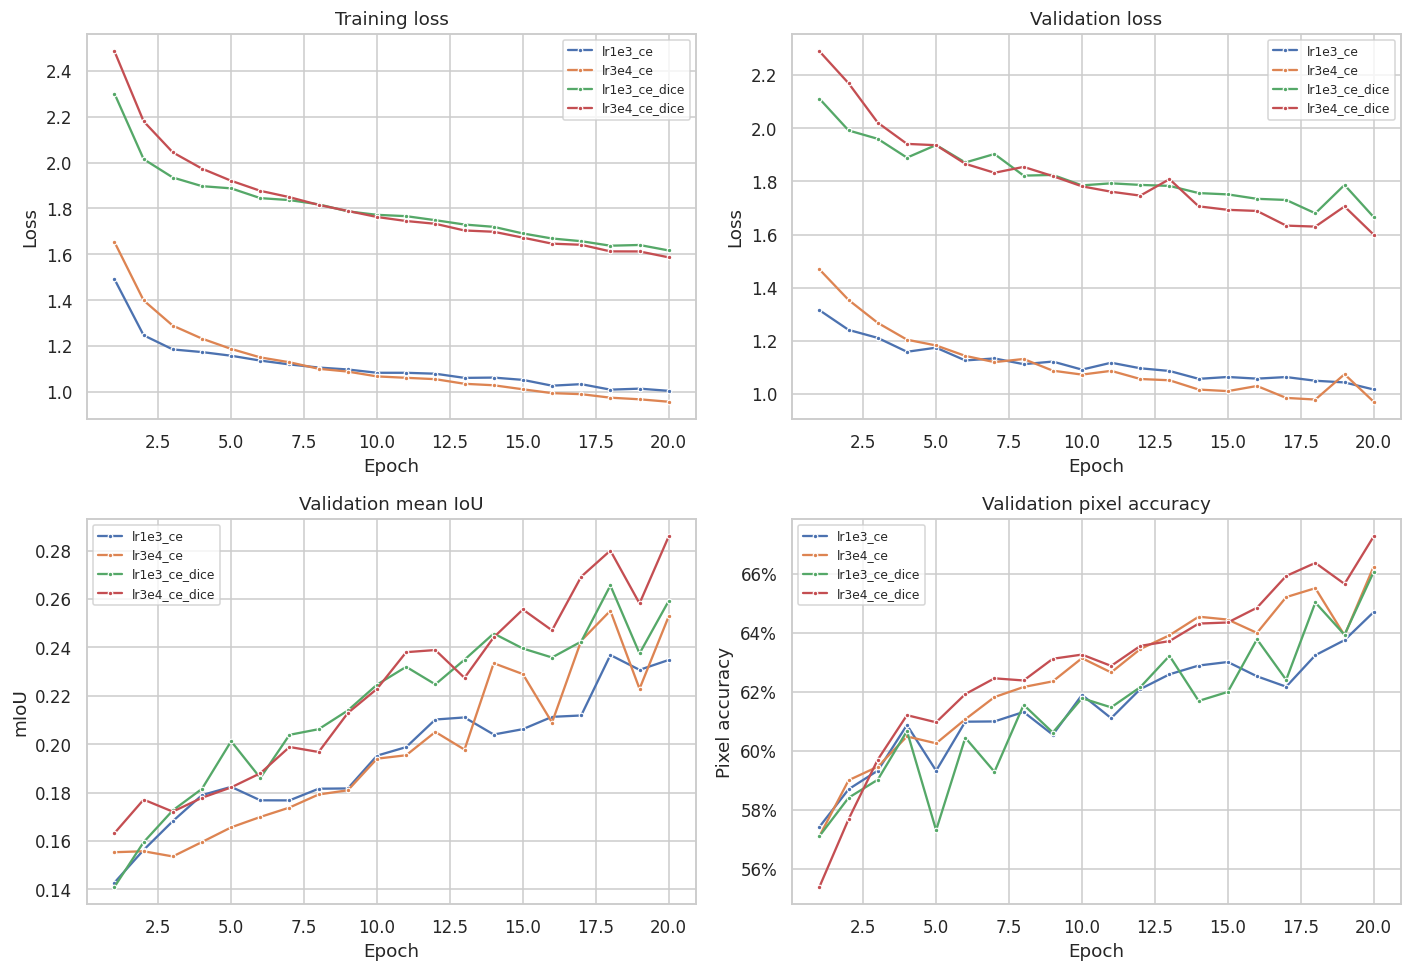

Selected trial: lr3e4_ce_dice


In [ ]:
tuning_histories=[]
for t in TRIALS:
    p=RUN_ROOT/'tuning'/t['name']/'history.csv'
    h=pd.read_csv(p)
    h['trial']=t['name']
    tuning_histories.append(h)
tuning_history=pd.concat(tuning_histories,ignore_index=True)
assert 'pixel_accuracy' in tuning_history.columns, 'Epoch-level pixel accuracy is missing.'
tuning_history.to_csv(RUN_ROOT/'tuning_all_epochs.csv',index=False)
fig,axes=plt.subplots(2,2,figsize=(13,9))
for ax,key,title,ylabel in zip(axes.flat,
    ['train_loss','val_loss','val_miou','pixel_accuracy'],
    ['Training loss','Validation loss','Validation mean IoU','Validation pixel accuracy'],
    ['Loss','Loss','mIoU','Pixel accuracy']):
    sns.lineplot(data=tuning_history,x='epoch',y=key,hue='trial',marker='o',markersize=3,ax=ax)
    ax.set(xlabel='Epoch',ylabel=ylabel,title=title)
    if key=='pixel_accuracy':
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v,pos:f'{v:.0%}'))
    ax.legend(fontsize=8)
plt.tight_layout();fig.savefig(RUN_ROOT/'tuning_learning_curves.png',bbox_inches='tight');plt.show()
print('Selected trial:',selection['selected_trial'])

## 7. Final U-Net training

I initialize a new U-Net and train it using the selected hyperparameters for up to 60 epochs. This run is independent of the tuning checkpoints. The optimizer, scheduler, early-stopping state, random states, and learning history are saved so training can resume after a Colab interruption. The best model is identified by validation mIoU, not by the final epoch.

In [ ]:
FINAL_EPOCHS=60
FINAL_PATIENCE=10
FINAL_OUT=RUN_ROOT/'final'
run_training(FINAL_OUT,selection['lr'],selection['loss'],FINAL_EPOCHS,FINAL_PATIENCE)
print('Best model:',FINAL_OUT/'best.pth')
print('Resumable model:',FINAL_OUT/'last.pth')

Starting final
Device: cuda; train=1204 val=214; parameters=1,942,696
Epoch 01/60 | train_loss=2.4845 val_loss=2.2754 | val_mIoU=0.1616 | pixel_acc=55.52% | best_mIoU=0.1616 (epoch 1) | lr=0.0003 | 31s
Epoch 02/60 | train_loss=2.1801 val_loss=2.1219 | val_mIoU=0.1654 | pixel_acc=58.45% | best_mIoU=0.1654 (epoch 2) | lr=0.0003 | 31s
Epoch 03/60 | train_loss=2.0422 val_loss=2.0297 | val_mIoU=0.1728 | pixel_acc=59.49% | best_mIoU=0.1728 (epoch 3) | lr=0.0003 | 32s
Epoch 04/60 | train_loss=1.9722 val_loss=1.9679 | val_mIoU=0.1770 | pixel_acc=60.81% | best_mIoU=0.1770 (epoch 4) | lr=0.0003 | 31s
Epoch 05/60 | train_loss=1.9224 val_loss=1.9060 | val_mIoU=0.1852 | pixel_acc=61.15% | best_mIoU=0.1852 (epoch 5) | lr=0.0003 | 31s
Epoch 06/60 | train_loss=1.8736 val_loss=1.8522 | val_mIoU=0.1922 | pixel_acc=62.10% | best_mIoU=0.1922 (epoch 6) | lr=0.0003 | 31s
Epoch 07/60 | train_loss=1.8490 val_loss=1.8318 | val_mIoU=0.1986 | pixel_acc=62.60% | best_mIoU=0.1986 (epoch 7) | lr=0.0003 | 32s
Epoch 

In [ ]:
# Extend final training from 60 to 120 epochs

FINAL_EPOCHS = 120
FINAL_PATIENCE = 10
FINAL_OUT = RUN_ROOT / "final"

assert (FINAL_OUT / "last.pth").exists(), "Checkpoint not found!"

run_training(
    FINAL_OUT,
    selection["lr"],
    selection["loss"],
    FINAL_EPOCHS,
    FINAL_PATIENCE
)

Resuming final
Resumed from epoch 60
Device: cuda; train=1204 val=214; parameters=1,942,696
Epoch 61/120 | train_loss=1.2621 val_loss=1.2964 | val_mIoU=0.3853 | pixel_acc=74.42% | best_mIoU=0.3853 (epoch 61) | lr=0.00015 | 33s
Epoch 62/120 | train_loss=1.2333 val_loss=1.3131 | val_mIoU=0.3799 | pixel_acc=74.13% | best_mIoU=0.3853 (epoch 61) | lr=0.00015 | 33s
Epoch 63/120 | train_loss=1.2539 val_loss=1.3112 | val_mIoU=0.3836 | pixel_acc=73.69% | best_mIoU=0.3853 (epoch 61) | lr=0.00015 | 32s
Epoch 64/120 | train_loss=1.2482 val_loss=1.3468 | val_mIoU=0.3727 | pixel_acc=73.63% | best_mIoU=0.3853 (epoch 61) | lr=0.00015 | 32s
Epoch 65/120 | train_loss=1.2374 val_loss=1.3015 | val_mIoU=0.3813 | pixel_acc=74.11% | best_mIoU=0.3853 (epoch 61) | lr=0.00015 | 32s
Epoch 66/120 | train_loss=1.2260 val_loss=1.3186 | val_mIoU=0.3807 | pixel_acc=74.21% | best_mIoU=0.3853 (epoch 61) | lr=7.5e-05 | 32s
Epoch 67/120 | train_loss=1.2197 val_loss=1.2821 | val_mIoU=0.3922 | pixel_acc=74.96% | best_mIoU=

## 8. Validation performance and training dynamics

I reload the best checkpoint and independently calculate its validation metrics. I compare training and validation losses, track mIoU and pixel accuracy over epochs, and inspect learning-rate changes. These plots help distinguish continued improvement from unstable training or potential overfitting.

Best epoch: 112 | validation mIoU: 0.4200 | pixel accuracy: 0.7567 | validation loss: 1.2238


,class,validation_iou
0,water,0.7772
1,diver,0.4915
2,plant,0.0000
3,wreck,0.5092
4,robot,0.0705
5,reef,0.6723
6,fish,0.4772
7,sea-floor,0.3621


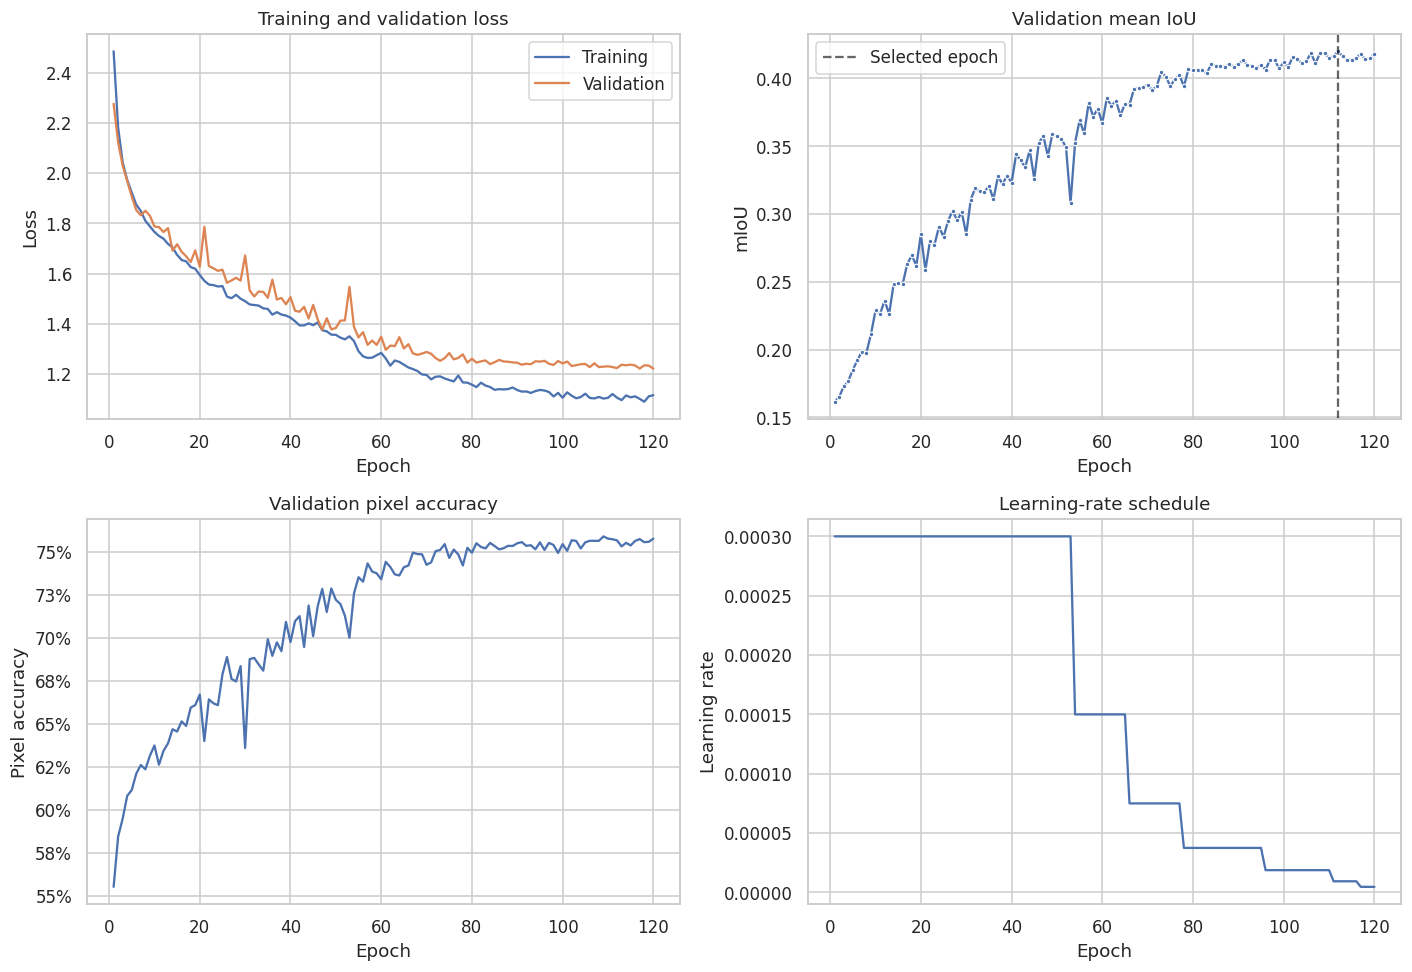

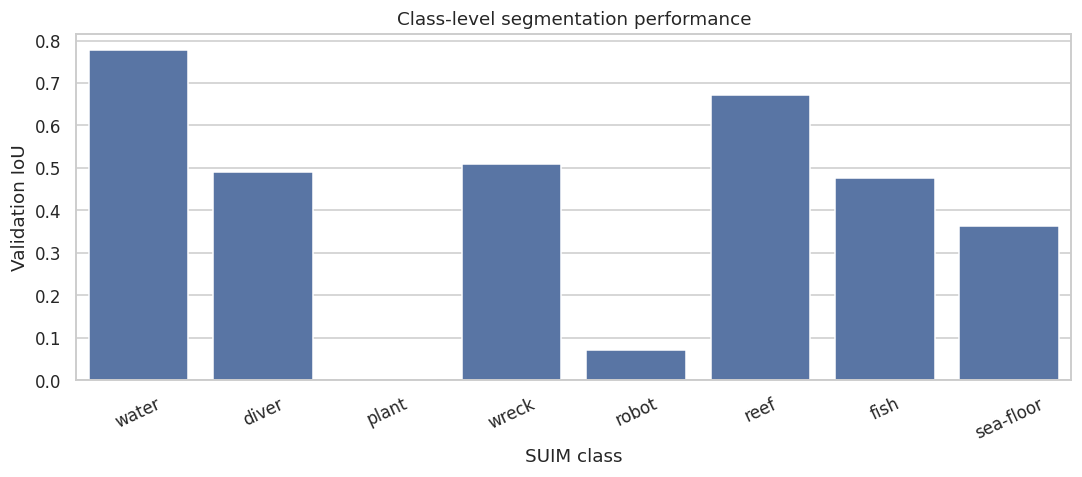

In [ ]:
history=pd.read_csv(FINAL_OUT/'history.csv')
summary=json.loads((FINAL_OUT/'best_validation.json').read_text())
checkpoint=torch.load(FINAL_OUT/'best.pth',map_location=DEVICE,weights_only=False)
assert checkpoint['config']['manifest']==str(MANIFEST)
assert checkpoint['config']['loss']==selection['loss']
model=SmallUNet().to(DEVICE)
model.load_state_dict(checkpoint['model']);model.eval()
from torch.utils.data import DataLoader
val_loader=DataLoader(SuimDataset('val',manifest=MANIFEST),batch_size=BATCH_SIZE,shuffle=False,num_workers=0)
val_loss,cm=evaluate(model,val_loader,DEVICE,selection['loss'])
per_class=iou_per_class(cm)
pixel_accuracy=float(np.trace(cm)/cm.sum())
assert np.isclose(miou(cm),summary['best_val_miou'],atol=1e-6)
print('Best epoch:',summary['best_epoch'],'| validation mIoU:',f'{miou(cm):.4f}',
      '| pixel accuracy:',f'{pixel_accuracy:.4f}','| validation loss:',f'{val_loss:.4f}')
class_table=pd.DataFrame({'class':CLASS_NAMES,'validation_iou':per_class})
display(class_table.style.format({'validation_iou':'{:.4f}'}))
class_table.to_csv(FINAL_OUT/'best_per_class_iou.csv',index=False)
metrics={'best_epoch':int(summary['best_epoch']),'validation_miou':miou(cm),
         'validation_pixel_accuracy':pixel_accuracy,'validation_loss':val_loss,
         'manifest_sha256':manifest_hash,'model':'SmallUNet(base=16)',
         'selected_configuration':selection}
(FINAL_OUT/'validated_metrics.json').write_text(json.dumps(metrics,indent=2))
fig,axes=plt.subplots(2,2,figsize=(13,9))
sns.lineplot(data=history,x='epoch',y='train_loss',ax=axes[0,0],label='Training')
sns.lineplot(data=history,x='epoch',y='val_loss',ax=axes[0,0],label='Validation')
axes[0,0].set(xlabel='Epoch',ylabel='Loss',title='Training and validation loss')
sns.lineplot(data=history,x='epoch',y='val_miou',marker='o',markersize=3,ax=axes[0,1])
axes[0,1].axvline(summary['best_epoch'],color='black',ls='--',alpha=.6,label='Selected epoch')
axes[0,1].legend();axes[0,1].set(xlabel='Epoch',ylabel='mIoU',title='Validation mean IoU')
sns.lineplot(data=history,x='epoch',y='pixel_accuracy',ax=axes[1,0])
axes[1,0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v,pos:f'{v:.0%}'))
axes[1,0].set(xlabel='Epoch',ylabel='Pixel accuracy',title='Validation pixel accuracy')
sns.lineplot(data=history,x='epoch',y='lr',ax=axes[1,1])
axes[1,1].set(xlabel='Epoch',ylabel='Learning rate',title='Learning-rate schedule')
plt.tight_layout();fig.savefig(FINAL_OUT/'training_curves.png',bbox_inches='tight');plt.show()
fig,ax=plt.subplots(figsize=(10,4.5))
sns.barplot(data=class_table,x='class',y='validation_iou',ax=ax,color=sns.color_palette()[0])
ax.set(xlabel='SUIM class',ylabel='Validation IoU',title='Class-level segmentation performance')
ax.tick_params(axis='x',rotation=25)
plt.tight_layout();fig.savefig(FINAL_OUT/'validation_per_class_iou.png',bbox_inches='tight');plt.show()

## 9. Class-level segmentation and error structure

Overall accuracy can obscure weak performance on rare classes. I therefore examine the IoU of each SUIM category and a row-normalized confusion matrix. Normalizing each ground-truth row makes class-specific confusions easier to compare despite unequal pixel frequencies.

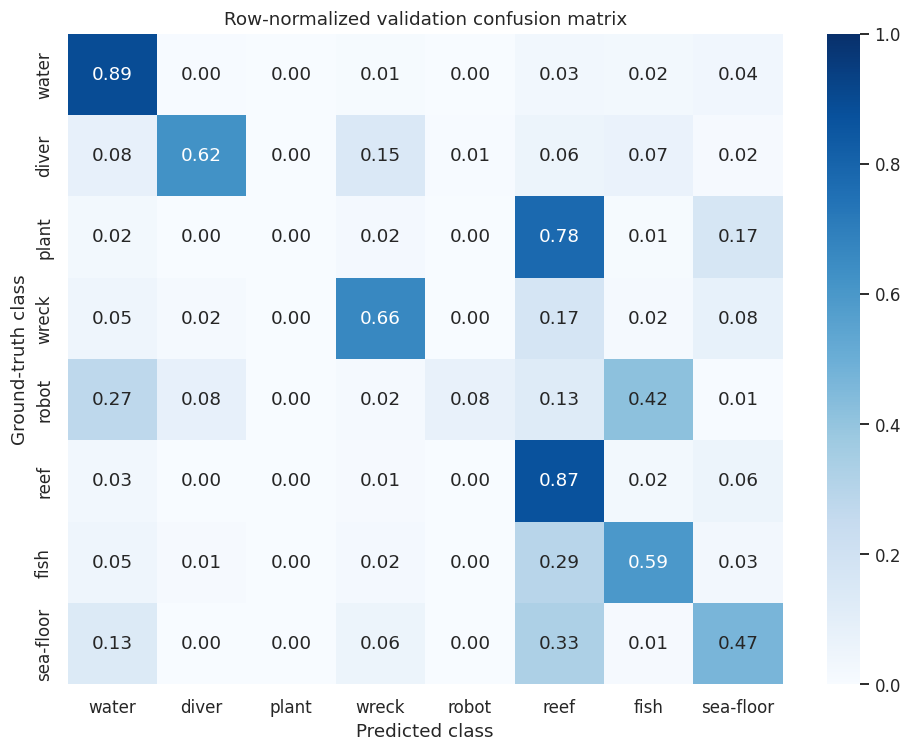

,class,validation_iou,validation_pixels
2,plant,0.000000,250857
4,robot,0.070501,51533
7,sea-floor,0.362102,2046931
6,fish,0.477224,1235696
1,diver,0.491515,244123
3,wreck,0.509202,981006
5,reef,0.672288,5260695
0,water,0.777209,3953863


In [ ]:
cm_df=pd.DataFrame(cm,index=CLASS_NAMES,columns=CLASS_NAMES)
cm_df.to_csv(FINAL_OUT/'validation_confusion_matrix_counts.csv')
row_totals=cm.sum(axis=1,keepdims=True)
normalized=np.divide(cm,row_totals,out=np.zeros_like(cm,dtype=float),where=row_totals!=0)
fig,ax=plt.subplots(figsize=(9,7))
sns.heatmap(normalized,annot=True,fmt='.2f',cmap='Blues',vmin=0,vmax=1,
            xticklabels=CLASS_NAMES,yticklabels=CLASS_NAMES,ax=ax)
ax.set(xlabel='Predicted class',ylabel='Ground-truth class',title='Row-normalized validation confusion matrix')
plt.tight_layout();fig.savefig(FINAL_OUT/'validation_confusion_matrix.png',bbox_inches='tight');plt.show()
class_table['validation_pixels']=cm.sum(axis=1)
display(class_table.sort_values('validation_iou'))

## 10. Qualitative validation analysis

I compare RAW validation images with their ground-truth masks and the selected model's predictions. These examples complement the numerical metrics by showing boundary quality, missed objects, and confusion between visually similar regions. The displayed examples are descriptive rather than a substitute for aggregate evaluation.

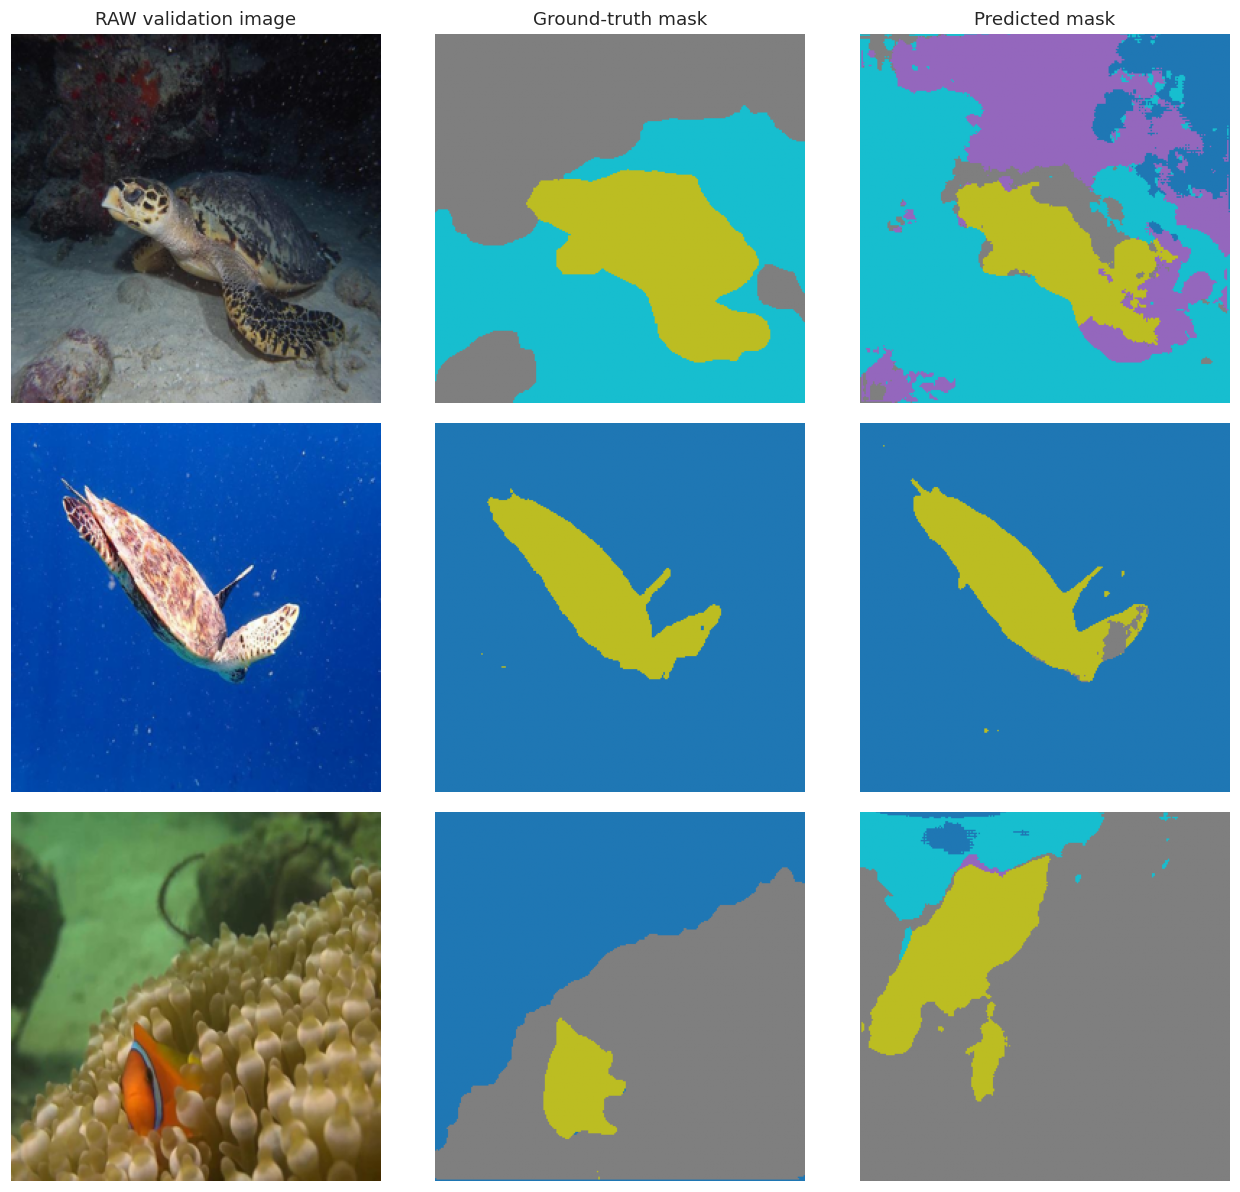

In [ ]:
fig,axes=plt.subplots(3,3,figsize=(12,11))
indices=[0,len(val_ds)//2,len(val_ds)-1]
for row,i in enumerate(indices):
    img,gt=val_ds[i]
    with torch.no_grad():pred=model(img.unsqueeze(0).to(DEVICE)).argmax(1).squeeze(0).cpu().numpy()
    axes[row,0].imshow((img.permute(1,2,0).numpy()+1)/2)
    axes[row,1].imshow(gt.numpy(),vmin=0,vmax=7,cmap='tab10')
    axes[row,2].imshow(pred,vmin=0,vmax=7,cmap='tab10')
    for a in axes[row]:a.axis('off')
for j,t in enumerate(['RAW validation image','Ground-truth mask','Predicted mask']):axes[0,j].set_title(t)
plt.tight_layout();fig.savefig(FINAL_OUT/'qualitative_validation.png',dpi=180,bbox_inches='tight');plt.show()


## 11. Investigation of Plant and Robot Segmentation Failures

### 11.1 Research Motivation

The final U-Net achieved a **validation mIoU of 42.00%** and **pixel accuracy of 75.67%**, with the best checkpoint selected at **epoch 112** after 120 training epochs.

However, the class-level evaluation revealed substantial differences in segmentation performance. In particular, the **plant class achieved 0.00% IoU**, while the **robot class achieved approximately 7.05% IoU**.

These findings indicate that the model performs considerably worse on these two categories than on water, reef, wreck, diver, and fish.

Although mean Intersection over Union (mIoU) provides an overall measure of segmentation performance, it does not explain the underlying causes of individual class failures.

I therefore investigate the plant and robot classes in greater detail to understand their representation, prediction behavior, and classification errors.

### 11.2 Research Questions

This investigation addresses four questions:

1. **Class representation:** How frequently do plant and robot pixels occur in the validation dataset?
2. **Prediction behavior:** Does the U-Net predict these classes, and how many predictions are correct?
3. **Class confusion:** Which other segmentation categories are predicted when the ground truth contains plant or robot?
4. **Qualitative errors:** What patterns can be observed when comparing the original underwater images, ground-truth masks, and predicted segmentation masks?

### 11.3 Diagnostic Methodology

I use the **best-performing U-Net checkpoint from epoch 112** and the existing RAW validation dataset to investigate these errors.

The quantitative analysis includes:

- **Ground-truth pixel frequency:** The number and proportion of pixels annotated as plant or robot.
- **Predicted pixel frequency:** The number of pixels assigned to each class by the model.
- **True positives (TP):** Pixels correctly assigned to the target class.
- **False positives (FP):** Pixels incorrectly predicted as the target class.
- **False negatives (FN):** Target-class pixels incorrectly assigned to another class.
- **Precision:** The proportion of predicted target-class pixels that are correct.
- **Recall:** The proportion of actual target-class pixels correctly identified.
- **Intersection over Union (IoU):** The overlap between predicted and ground-truth target regions.

I additionally examine the **class confusion distributions** to identify which categories most frequently replace plant and robot in the predictions.

For qualitative evaluation, I select validation images containing these classes and compare:

1. **RAW underwater images**
2. **Ground-truth segmentation masks**
3. **U-Net predicted segmentation masks**
4. **Class-specific error maps**

The error maps distinguish correctly predicted target pixels, missed target pixels, and incorrectly assigned target-class pixels.

### 11.4 Potential Explanations

Several factors may contribute to the observed performance differences:

- **Class imbalance:** Plant and robot may occupy fewer pixels or appear in fewer training images than dominant categories.
- **Visual similarity:** Underwater vegetation may share textures, colors, and boundaries with reefs or other surrounding regions.
- **Image resolution:** Resizing to **256 × 256 pixels** may reduce fine structural details needed to distinguish small or thin objects.
- **Model optimization:** The combined Cross-Entropy and Dice loss may not fully compensate for differences in class representation or segmentation difficulty.
- **Environmental conditions:** Underwater color distortion, turbidity, and low contrast may obscure important visual features.

**These are possible explanations rather than established causes.** I will interpret them only in relation to the quantitative and qualitative evidence obtained from the diagnostic analysis.

### 11.5 Experimental Integrity

This investigation uses the **existing frozen U-Net**, without retraining or modifying the selected checkpoint.

All diagnostic calculations and visualizations are performed using the **RAW validation dataset**. The official test dataset remains untouched.

This preserves the experimental design for the subsequent comparison of RAW, CLAHE, and FUnIE-GAN image conditions.


,class,ground_truth_pixels,predicted_pixels,true_positives,false_positives,false_negatives,precision,recall,iou,validation_pixel_share
0,plant,250857,0,0,0,250857,0.0000,0.0000,0.0000,0.0179
1,robot,51533,8885,3979,4906,47554,0.4478,0.0772,0.0705,0.0037


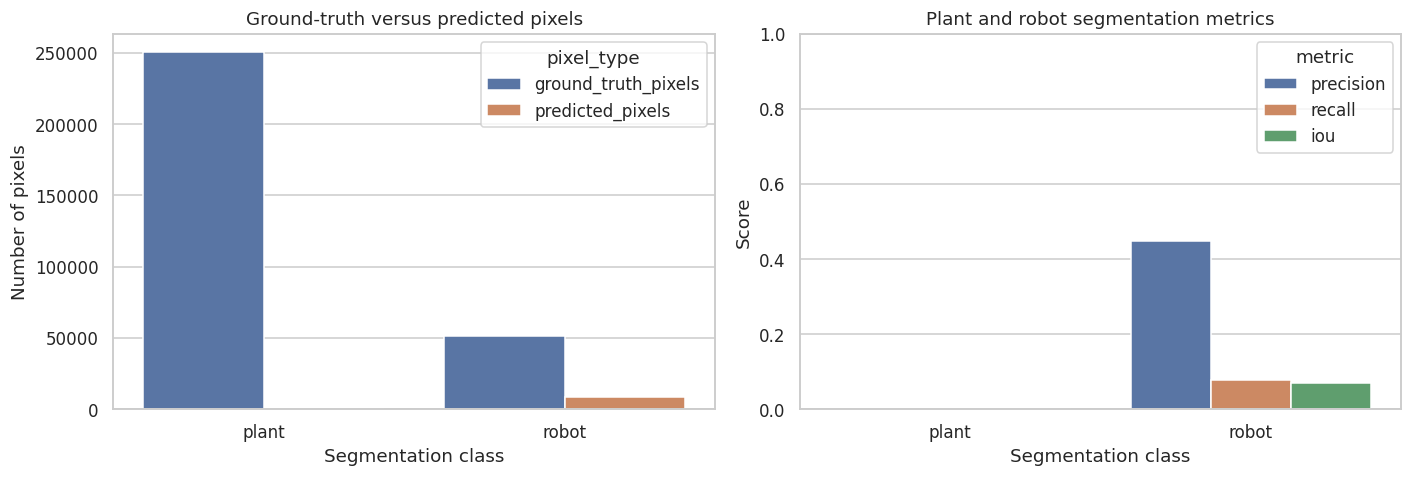


PLANT — Most frequent predicted classes


,predicted_class,proportion
5,reef,0.7784
7,sea-floor,0.1662
0,water,0.0246
3,wreck,0.0213
6,fish,0.0080



ROBOT — Most frequent predicted classes


,predicted_class,proportion
6,fish,0.4152
0,water,0.2740
5,reef,0.1284
1,diver,0.0832
4,robot,0.0772


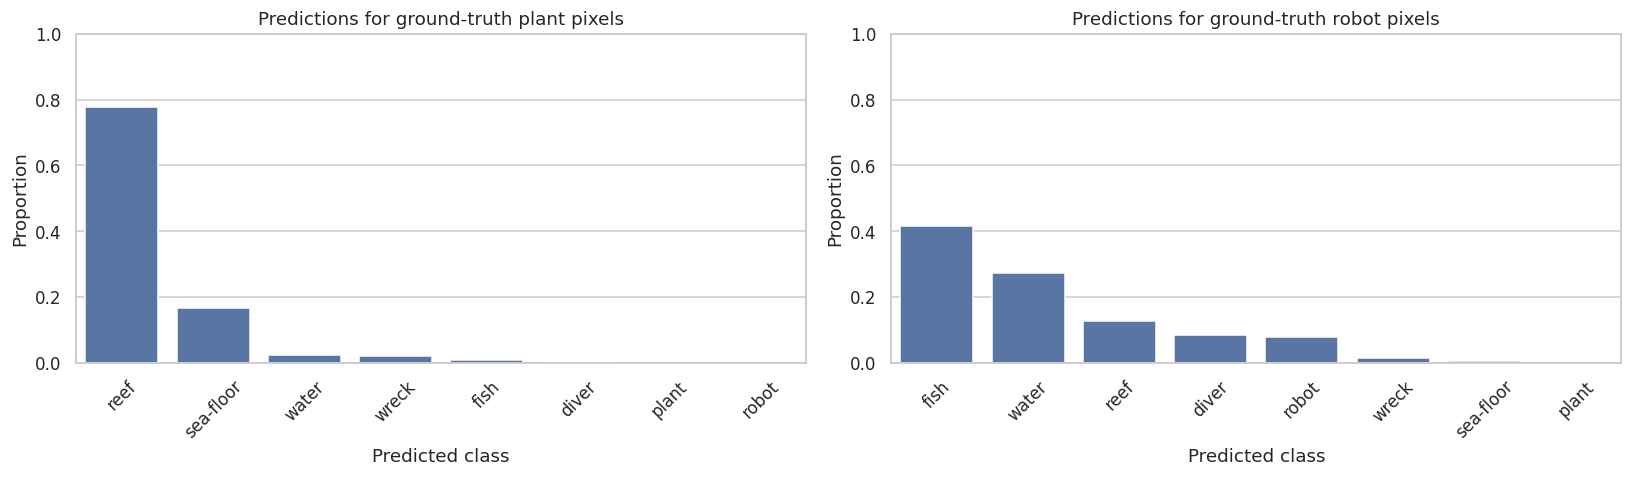

In [ ]:

# Section 11.4 - Plant and robot quantitative diagnostics

TARGET_CLASSES = ["plant", "robot"]
target_ids = [CLASS_NAMES.index(name) for name in TARGET_CLASSES]

diagnostic_rows = []
for name, idx in zip(TARGET_CLASSES, target_ids):
    tp = int(cm[idx, idx])
    gt_pixels = int(cm[idx, :].sum())
    predicted_pixels = int(cm[:, idx].sum())
    fp = predicted_pixels - tp
    fn = gt_pixels - tp

    precision = tp / predicted_pixels if predicted_pixels else 0.0
    recall = tp / gt_pixels if gt_pixels else 0.0
    iou = tp / (tp + fp + fn) if (tp + fp + fn) else np.nan

    diagnostic_rows.append({
        "class": name,
        "ground_truth_pixels": gt_pixels,
        "predicted_pixels": predicted_pixels,
        "true_positives": tp,
        "false_positives": fp,
        "false_negatives": fn,
        "precision": precision,
        "recall": recall,
        "iou": iou,
        "validation_pixel_share": gt_pixels / cm.sum()
    })

diagnostics = pd.DataFrame(diagnostic_rows)
display(diagnostics.round(4))

diagnostics.to_csv(
    FINAL_OUT / "plant_robot_diagnostics.csv",
    index=False
)

# Ground-truth pixels and predicted pixels
counts_long = diagnostics.melt(
    id_vars="class",
    value_vars=["ground_truth_pixels", "predicted_pixels"],
    var_name="pixel_type",
    value_name="pixels"
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.barplot(
    data=counts_long,
    x="class",
    y="pixels",
    hue="pixel_type",
    ax=axes[0]
)
axes[0].set(
    title="Ground-truth versus predicted pixels",
    xlabel="Segmentation class",
    ylabel="Number of pixels"
)

metrics_long = diagnostics.melt(
    id_vars="class",
    value_vars=["precision", "recall", "iou"],
    var_name="metric",
    value_name="score"
)

sns.barplot(
    data=metrics_long,
    x="class",
    y="score",
    hue="metric",
    ax=axes[1]
)
axes[1].set(
    title="Plant and robot segmentation metrics",
    xlabel="Segmentation class",
    ylabel="Score",
    ylim=(0, 1)
)

plt.tight_layout()
fig.savefig(
    FINAL_OUT / "plant_robot_metrics.png",
    bbox_inches="tight"
)
plt.show()

# Which classes replace plant and robot?
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

for ax, name, idx in zip(axes, TARGET_CLASSES, target_ids):
    distribution = cm[idx].astype(float)
    distribution /= max(distribution.sum(), 1)

    confusion_df = pd.DataFrame({
        "predicted_class": CLASS_NAMES,
        "proportion": distribution
    }).sort_values("proportion", ascending=False)

    sns.barplot(
        data=confusion_df,
        x="predicted_class",
        y="proportion",
        color=sns.color_palette("deep")[0],
        ax=ax
    )

    ax.set(
        title=f"Predictions for ground-truth {name} pixels",
        xlabel="Predicted class",
        ylabel="Proportion",
        ylim=(0, 1)
    )
    ax.tick_params(axis="x", rotation=45)

    print(f"\n{name.upper()} — Most frequent predicted classes")
    display(confusion_df.head(5).round(4))

plt.tight_layout()
fig.savefig(
    FINAL_OUT / "plant_robot_class_confusion.png",
    bbox_inches="tight"
)
plt.show()


In [ ]:

# Section 11.5 - Targeted qualitative error analysis

from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

assert model.training is False, "The model must be in evaluation mode."

def inspect_class_examples(class_name, n_examples=4):
    class_id = CLASS_NAMES.index(class_name)
    candidates = []

    for i in range(len(val_ds)):
        _, mask = val_ds[i]
        count = int((mask == class_id).sum().item())
        if count > 0:
            candidates.append((i, count))

    candidates.sort(key=lambda item: item[1], reverse=True)
    selected = candidates[:n_examples]

    print(
        f"{class_name.upper()}: "
        f"{len(candidates)} validation images contain this class."
    )

    if not selected:
        print("No annotated examples were found.")
        return

    fig, axes = plt.subplots(
        len(selected), 4,
        figsize=(16, 4 * len(selected)),
        squeeze=False
    )

    error_cmap = ListedColormap([
        "#D9D9D9",  # Neither
        "#2CA02C",  # True positive
        "#D62728",  # False negative
        "#1F77B4"   # False positive
    ])

    for row, (idx, pixel_count) in enumerate(selected):
        image, ground_truth = val_ds[idx]

        with torch.inference_mode():
            prediction = model(
                image.unsqueeze(0).to(DEVICE)
            ).argmax(dim=1).squeeze(0).cpu().numpy()

        gt = ground_truth.numpy()
        raw = np.clip(
            (image.permute(1, 2, 0).numpy() + 1) / 2,
            0, 1
        )

        gt_target = gt == class_id
        pred_target = prediction == class_id

        error_map = np.zeros_like(gt, dtype=np.uint8)
        error_map[gt_target & pred_target] = 1
        error_map[gt_target & ~pred_target] = 2
        error_map[~gt_target & pred_target] = 3

        axes[row, 0].imshow(raw)
        axes[row, 1].imshow(gt, cmap="tab10", vmin=0, vmax=7)
        axes[row, 2].imshow(prediction, cmap="tab10", vmin=0, vmax=7)
        axes[row, 3].imshow(
            error_map,
            cmap=error_cmap,
            vmin=0,
            vmax=3,
            interpolation="nearest"
        )

        axes[row, 0].set_ylabel(
            f"Image {idx}\n{pixel_count:,} {class_name} pixels",
            fontsize=10
        )

        for ax in axes[row]:
            ax.axis("off")

    for ax, title in zip(
        axes[0],
        ["RAW image", "Ground truth", "U-Net prediction",
         f"{class_name.title()} error map"]
    ):
        ax.set_title(title, fontsize=12, weight="bold")

    legend_items = [
        Patch(color="#2CA02C", label="Correct target pixels"),
        Patch(color="#D62728", label="Missed target pixels"),
        Patch(color="#1F77B4", label="Incorrect target predictions")
    ]

    fig.legend(
        handles=legend_items,
        loc="lower center",
        ncol=3,
        bbox_to_anchor=(0.5, 0.01)
    )

    fig.suptitle(
        f"{class_name.title()} segmentation investigation",
        fontsize=15,
        weight="bold"
    )

    plt.tight_layout(rect=(0, 0.06, 1, 0.96))
    fig.savefig(
        FINAL_OUT / f"{class_name}_error_examples.png",
        dpi=180,
        bbox_inches="tight"
    )
    plt.show()

inspect_class_examples("plant")
inspect_class_examples("robot")


Output hidden; open in https://colab.research.google.com to view.

In [ ]:

# Section 11.6 - Diagnostic findings

for _, row in diagnostics.iterrows():
    name = row["class"]
    idx = CLASS_NAMES.index(name)

    gt_count = int(row["ground_truth_pixels"])
    predicted_count = int(row["predicted_pixels"])
    tp = int(row["true_positives"])

    confusion = pd.Series(
        cm[idx],
        index=CLASS_NAMES
    ).drop(name).sort_values(ascending=False)

    dominant_class = confusion.index[0]
    dominant_count = int(confusion.iloc[0])
    dominant_share = dominant_count / gt_count if gt_count else 0

    print(f"\n{name.upper()} CLASS FINDINGS")
    print("-" * 45)
    print(f"Ground-truth pixels: {gt_count:,}")
    print(f"Predicted pixels: {predicted_count:,}")
    print(f"Correctly predicted pixels: {tp:,}")
    print(f"Precision: {row['precision']:.2%}")
    print(f"Recall: {row['recall']:.2%}")
    print(f"IoU: {row['iou']:.2%}")
    print(
        f"Most common incorrect prediction: "
        f"{dominant_class} ({dominant_share:.2%} of "
        f"ground-truth {name} pixels)"
    )

    if predicted_count == 0:
        print(
            "Observation: The model never predicts this class "
            "on the validation set."
        )
    elif tp == 0:
        print(
            "Observation: The model predicts this class, "
            "but none of those predictions overlap its "
            "ground-truth pixels."
        )
    else:
        print(
            "Observation: The model recognizes some pixels "
            "correctly but misses or misclassifies others."
        )

print(
    "\nThese findings describe the frozen U-Net on RAW "
    "validation images only."
)



PLANT CLASS FINDINGS
---------------------------------------------
Ground-truth pixels: 250,857
Predicted pixels: 0
Correctly predicted pixels: 0
Precision: 0.00%
Recall: 0.00%
IoU: 0.00%
Most common incorrect prediction: reef (77.84% of ground-truth plant pixels)
Observation: The model never predicts this class on the validation set.

ROBOT CLASS FINDINGS
---------------------------------------------
Ground-truth pixels: 51,533
Predicted pixels: 8,885
Correctly predicted pixels: 3,979
Precision: 44.78%
Recall: 7.72%
IoU: 7.05%
Most common incorrect prediction: fish (41.52% of ground-truth robot pixels)
Observation: The model recognizes some pixels correctly but misses or misclassifies others.

These findings describe the frozen U-Net on RAW validation images only.



## 12. Discussion and Limitations

### 12.1 Overall Baseline Performance

In this study, I developed and evaluated a U-Net baseline for eight-class underwater semantic segmentation using RAW images from the SUIM dataset.

Following hyperparameter optimization, I selected a learning rate of **0.0003** with a combined **Cross-Entropy and Dice loss**. The final model was trained for 120 epochs, with the best checkpoint obtained at **epoch 112**.

The selected model achieved:

- **Validation mIoU:** 42.00%
- **Validation pixel accuracy:** 75.67%
- **Validation loss:** 1.2238

These results indicate that the U-Net learned useful segmentation representations for several underwater categories. However, the difference between overall pixel accuracy and mean IoU highlights the importance of evaluating individual classes rather than relying on a single performance measure.

The improvement from **28.59% mIoU during hyperparameter tuning to 42.00% during final training** also demonstrates the benefit of extending training beyond the initial 20-epoch optimization experiments.

### 12.2 Differences in Class-Level Performance

The model demonstrated considerable variation across the eight segmentation categories.

**Water achieved the highest IoU (77.72%)**, followed by **reef (67.23%)**, wreck (50.92%), diver (49.15%), fish (47.72%), and sea-floor (36.21%).

In contrast, **robot achieved only 7.05% IoU**, while **plant achieved 0.00% IoU**.

These results show that the model's ability to segment underwater scenes is uneven. Strong performance on water and reef does not necessarily translate into reliable recognition of smaller or more visually complex categories.

The class-level findings are particularly relevant to underwater robotic perception, where correctly identifying objects and environmental structures may be more important than maximizing overall pixel accuracy.

### 12.3 Plant-Class Failure Investigation

The targeted diagnostic analysis revealed that **plant was never predicted by the selected U-Net on the validation dataset**.

Although the ground-truth annotations contained **250,857 plant pixels**, the model assigned zero pixels to the plant category.

Consequently, plant precision, recall, and IoU were all recorded as **0.00%**.

The confusion analysis showed that ground-truth plant pixels were predominantly assigned to other categories:

- **Reef:** 77.84%
- **Sea-floor:** 16.62%
- **Water:** 2.46%
- **Wreck:** 2.13%
- **Fish:** 0.80%

This confirms that the plant failure is not simply a matter of producing inaccurate plant boundaries. Instead, the model **completely omits the plant category from its validation predictions**.

The strong confusion with reef suggests that the model may have difficulty distinguishing underwater vegetation from surrounding reef structures.

However, this explanation remains a hypothesis. The observed confusion establishes what the model predicts incorrectly, but it does not independently establish why the error occurs.

Plant accounts for approximately **1.79% of annotated validation pixels**, which may also contribute to its poor representation during optimization. Nevertheless, validation frequency alone is insufficient to establish training-set class imbalance as the cause.

The qualitative error maps complement these findings by illustrating missed plant regions in individual validation images.

**The complete absence of plant predictions is a significant limitation of the baseline and should be explicitly considered when interpreting subsequent enhancement results.**

### 12.4 Robot-Class Failure Investigation

Unlike plant, the robot class was predicted by the model, although recognition remained limited.

The validation dataset contained **51,533 ground-truth robot pixels**, while the model predicted **8,885 pixels** as robot.

Of these predictions, **3,979 pixels were correct**, resulting in:

- **Precision:** 44.78%
- **Recall:** 7.72%
- **IoU:** 7.05%

The relatively higher precision compared with recall indicates that some robot predictions were correct, but the model failed to identify most annotated robot pixels.

The confusion analysis revealed that ground-truth robot pixels were most frequently predicted as:

- **Fish:** 41.52%
- **Water:** 27.40%
- **Reef:** 12.84%
- **Diver:** 8.32%

Only **7.72% of ground-truth robot pixels** were correctly recognized.

These findings indicate that the primary robot-class problem is **low detection coverage**, rather than a complete absence of predictions.

Robot pixels represent approximately **0.37% of the validation annotations**, making this one of the least represented categories in the evaluated partition.

Possible contributing factors include limited class representation, visual similarity with other underwater objects, differences in object appearance, and the loss of fine details during image resizing.

However, additional investigation of the training annotations and model representations would be required to determine the relative contribution of these factors.

### 12.5 Implications for Underwater Image Enhancement

The baseline results provide an important foundation for investigating whether underwater image enhancement affects semantic segmentation.

The model performs relatively well on some categories but struggles substantially with plant and robot recognition.

This creates an opportunity to examine whether image enhancement improves segmentation in difficult visual conditions or introduces additional distortions that reduce model performance.

For example, improved contrast or color restoration may make some object boundaries more distinguishable. Conversely, enhancement may alter image characteristics in ways that are inconsistent with the RAW images used during training.

**These possibilities have not yet been tested and should not be interpreted as established findings.**

In the subsequent experiments, I will apply the **same frozen U-Net checkpoint** to the same official test images under three conditions:

1. **RAW:** Original underwater images without enhancement.
2. **CLAHE:** Contrast Limited Adaptive Histogram Equalization.
3. **FUnIE-GAN:** Pretrained learning-based underwater image enhancement.

By keeping the model weights and evaluation images unchanged, I can isolate the effect of the input image condition on segmentation performance.

Particular attention will be given to **plant and robot IoU, recall, and confusion patterns**, alongside overall mIoU and pixel accuracy.

### 12.6 Study Limitations

Several limitations should be considered when interpreting the baseline results.

**1. Class imbalance and representation**

Plant and robot occupy relatively small proportions of the validation annotations. This may affect model performance, although the training-set distribution must also be examined before establishing class imbalance as an explanation.

**2. Limited hyperparameter optimization**

The optimization procedure evaluated four combinations of learning rate and loss function. Other configurations, architectures, and training strategies may achieve better performance.

**3. Input image resolution**

Images were resized to **256 × 256 pixels**. This may reduce fine spatial details, particularly for thin vegetation structures, small robotic objects, and complex object boundaries.

**4. Uneven class-level recognition**

The selected model completely failed to predict plant and achieved low recall for robot. These weaknesses limit its reliability across all eight categories.

**5. Validation-based evaluation**

All performance metrics reported in this notebook were calculated using the validation partition. They do not represent final performance on the official test dataset.

**6. Unconfirmed causes of segmentation failure**

The diagnostic analysis identifies class omission, low recall, and systematic confusion patterns. However, it does not conclusively establish whether these failures arise from training-set imbalance, visual similarity, annotation characteristics, architectural limitations, or optimization behavior.

**7. Single baseline architecture**

The study evaluates one U-Net architecture. Therefore, subsequent findings will describe the effect of enhancement on this specific trained model rather than establish that the same behavior applies to all segmentation architectures.

### 12.7 Discussion Summary

The selected U-Net achieved **42.00% validation mIoU**, demonstrating meaningful segmentation capability across several underwater categories.

However, the targeted investigation revealed two distinct failure patterns:

- **Plant:** Complete prediction omission, with most annotated pixels classified as reef.
- **Robot:** Limited recognition characterized by low recall and frequent confusion with fish and water.

These findings demonstrate why **class-level evaluation is essential in underwater semantic segmentation research**.

The baseline is suitable for the planned controlled enhancement comparison, provided its limitations are reported transparently and the results are interpreted in the context of the selected model.


In [ ]:
best=class_table.dropna(subset=['validation_iou']).sort_values('validation_iou')
lowest=best.iloc[0]
highest=best.iloc[-1]
print(f"The selected model achieved validation mIoU {miou(cm):.3f} and pixel accuracy {pixel_accuracy:.1%}.")
print(f"Highest class IoU: {highest['class']} ({highest['validation_iou']:.3f}).")
print(f"Lowest class IoU: {lowest['class']} ({lowest['validation_iou']:.3f}).")
print(f"Best validation checkpoint was obtained at epoch {summary['best_epoch']} of {len(history)} completed epochs.")
print('These results describe RAW validation performance only; enhancement effects remain untested.')

The selected model achieved validation mIoU 0.420 and pixel accuracy 75.7%.
Highest class IoU: water (0.777).
Lowest class IoU: plant (0.000).
Best validation checkpoint was obtained at epoch 112 of 120 completed epochs.
These results describe RAW validation performance only; enhancement effects remain untested.



## 13. Conclusion and Research Handoff

### 13.1 Research Conclusion

In this notebook, I established a reproducible U-Net baseline for eight-class underwater semantic segmentation using the cleaned SUIM dataset.

The experimental workflow included dataset integrity verification, architecture inspection, controlled hyperparameter optimization, final model training, validation-based checkpoint selection, class-level evaluation, and qualitative segmentation analysis.

I also conducted a targeted investigation of plant and robot segmentation failures to better understand the limitations of the selected model.

The best-performing configuration used a **learning rate of 0.0003** and a combined **Cross-Entropy and Dice loss**.

Following 120 training epochs, the selected checkpoint from **epoch 112** achieved:

| Evaluation metric | Result |
|---|---:|
| **Validation mIoU** | **42.00%** |
| **Validation pixel accuracy** | **75.67%** |
| **Validation loss** | **1.2238** |
| Best checkpoint | Epoch 112 |
| Total training epochs | 120 |

The results demonstrate that the U-Net learned meaningful segmentation features for several underwater categories, particularly water and reef.

However, the class-level analysis revealed significant weaknesses in plant and robot recognition.

**Plant was never predicted on the validation dataset**, resulting in 0.00% IoU. Most ground-truth plant pixels were incorrectly classified as reef.

**Robot achieved 7.05% IoU and 7.72% recall**, indicating that the model correctly identified some robot pixels but missed most annotated robot regions.

These findings establish that overall segmentation performance can conceal substantial category-specific failures.

The model therefore provides a reproducible experimental baseline, rather than a fully reliable underwater segmentation system.

### 13.2 Research Artifacts and Reproducibility

The notebook preserves the experimental outputs needed to reproduce and interpret the baseline results.

These include:

- **Selected hyperparameter configuration** and tuning comparison results.
- **Training histories** containing epoch-level losses, validation mIoU, pixel accuracy, and learning rates.
- **Best and latest model checkpoints**, including the selected epoch-112 checkpoint.
- **Validation metrics** and per-class IoU results.
- **Confusion matrix** and class-level segmentation visualizations.
- **Qualitative predictions** comparing RAW images, ground-truth masks, and U-Net outputs.
- **Plant and robot diagnostic results**, including pixel counts, precision, recall, IoU, confusion distributions, and error visualizations.

The best model checkpoint is retained as the baseline for subsequent experiments.

No additional model training is required for the planned comparison of RAW and enhanced images.

### 13.3 Handoff to Notebook 03: Underwater Image Enhancement

The next notebook will investigate two underwater image enhancement approaches:

**1. Contrast Limited Adaptive Histogram Equalization (CLAHE)**

CLAHE will be used to improve local image contrast while limiting excessive amplification within local regions.

**2. FUnIE-GAN**

A pretrained FUnIE-GAN model will be used to generate learning-based enhanced versions of underwater images.

The enhancement procedures will be applied consistently and documented to support reproducibility.

The objective of Notebook 03 is to prepare the enhanced image conditions, not to retrain or optimize the U-Net.

### 13.4 Handoff to Notebook 04: Controlled Segmentation Evaluation

Notebook 04 will load the **selected epoch-112 U-Net checkpoint** and evaluate the official test images under three conditions:

| Condition | Input representation | Segmentation model |
|---|---|---|
| RAW | Original underwater images | Frozen U-Net |
| CLAHE | Contrast-enhanced images | Same frozen U-Net |
| FUnIE-GAN | Learning-based enhanced images | Same frozen U-Net |

All three conditions will use:

- The **same official test images**.
- The **same ground-truth segmentation masks**.
- The **same trained U-Net weights**.
- The **same preprocessing dimensions and evaluation metrics**.

The evaluation will compare overall mIoU, pixel accuracy, class-level IoU, and segmentation error patterns.

Special attention will be given to whether enhancement changes performance for **plant and robot**, the two weakest categories identified during baseline validation.

Any observed improvement or deterioration will be interpreted relative to the RAW test condition.

### 13.5 Handoff to Notebook 05: Critical Analysis

The final notebook will synthesize the segmentation results across the three image conditions.

The analysis will address the central research question:

**Does underwater image enhancement improve CNN-based semantic segmentation performance, or can it introduce changes that reduce segmentation accuracy?**

I will examine overall performance differences, class-specific changes, qualitative prediction errors, and the limitations of using a fixed model trained on RAW underwater imagery.

The analysis will distinguish measurable improvements from visually appealing enhancement effects, since an image that appears clearer to a human observer does not necessarily produce more accurate segmentation.

### 13.6 Final Research Position

The completed baseline provides a controlled foundation for evaluating the relationship between underwater image enhancement and semantic segmentation.

Its main findings are:

1. **Extended training improved validation performance**, with the selected U-Net achieving 42.00% mIoU.
2. **Segmentation accuracy varied considerably across classes**, despite an overall pixel accuracy of 75.67%.
3. **Plant was completely omitted from validation predictions**, while robot recognition remained limited.
4. **The model's weaknesses were quantified through targeted diagnostics**, providing specific categories to monitor during enhancement evaluation.
5. **The official test set remains reserved for the controlled comparison**, preserving the separation between model development and final evaluation.

**The next stage is to evaluate whether changing underwater image appearance improves segmentation performance when the trained U-Net remains unchanged.**


In [ ]:
required=[RUN_ROOT/'selected_configuration.json',RUN_ROOT/'tuning_comparison.csv',
          RUN_ROOT/'tuning_learning_curves.png',RUN_ROOT/'tuning_all_epochs.csv',
          FINAL_OUT/'best.pth',FINAL_OUT/'last.pth',FINAL_OUT/'history.csv',
          FINAL_OUT/'best_validation.json',FINAL_OUT/'validated_metrics.json',
          FINAL_OUT/'training_curves.png',FINAL_OUT/'validation_per_class_iou.png',
          FINAL_OUT/'validation_confusion_matrix.png',FINAL_OUT/'qualitative_validation.png']
missing=[str(p) for p in required if not p.exists()]
assert not missing, f'Missing research outputs: {missing}'
print('Research outputs verified:',len(required))
print('Selected baseline checkpoint:',FINAL_OUT/'best.pth')

Research outputs verified: 13
Selected baseline checkpoint: /content/drive/MyDrive/Underwater_Research/checkpoints/notebook_02_public_research_v1/final/best.pth
